# Actual-Error Validation for Problem 2

This notebook is for paper reporting. It uses saved Problem 2 allocations and decision trees, keeps every strategy fixed, and reevaluates those fixed trees with actual Helstrom branch probabilities.

It does not generate new instances and does not re-optimize with actual error.


In [1]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
project_directory = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
source_directory = project_directory / "src"
if str(source_directory) not in sys.path:
    sys.path.insert(0, str(source_directory))

# Reload algorithm modules before reloading the analysis wrapper.
import heuristic
heuristic = importlib.reload(heuristic)

import actual_error_analysis
actual_error_analysis = importlib.reload(actual_error_analysis)

run_actual_error = actual_error_analysis.run_actual_error_evaluation
actual_error_summary = actual_error_analysis.actual_error_summary
actual_method_comparison_summary = actual_error_analysis.actual_method_comparison_summary
surrogate_quality_summary = actual_error_analysis.surrogate_quality_summary
bias_mae_summary = actual_error_analysis.bias_mae_summary
within_budget_correlation_summary = actual_error_analysis.within_budget_correlation_summary
method_ranking_agreement_summary = actual_error_analysis.method_ranking_agreement_summary
residual_by_k_summary = actual_error_analysis.residual_by_k_summary

print("Project directory:", project_directory)
print("Source directory:", source_directory)
print("Using actual_error_analysis from:", actual_error_analysis.__file__)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src
Using actual_error_analysis from: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src/actual_error_analysis.py


## Settings

Use `COMPACT_RUN_SCOPE` to switch between saved compact pilot records (`"test"`) and saved full compact records (`"full"`). This notebook is compact-only and includes Exhaustive, Greedy, Tree-aware heuristic, Uniform, and Random because those strategies are saved by the compact comparison pipeline.

The optional expanded section is disabled by default. It has no Exhaustive-search solution, so it reports Greedy, Tree-aware heuristic, Uniform, and Random only.


In [2]:
# Compact data: includes Exhaustive, Greedy, Tree-aware heuristic, Uniform, and Random.
COMPACT_DATASETS = ("compact_benchmark_1d", "compact_benchmark_2d")
COMPACT_RUN_SCOPE = "full"  # switch to "test" for the compact pilot records

if COMPACT_RUN_SCOPE not in {"test", "full"}:
    raise ValueError('COMPACT_RUN_SCOPE must be "test" or "full"')

COMPACT_RESULTS_ROOT = project_directory / "results" / "cmp_compact"
ACTUAL_RESULTS_ROOT = project_directory / "results" / "actual_error"

print("Compact scope:", COMPACT_RUN_SCOPE)
print("Reading compact saved allocations/trees from:", COMPACT_RESULTS_ROOT)
print("Writing paper outputs under:", ACTUAL_RESULTS_ROOT)


Compact scope: full
Reading compact saved allocations/trees from: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_compact
Writing paper outputs under: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/actual_error


## Compute Compact Actual Errors

This cell loads the saved compact allocations and decision trees from the previous Problem 2 comparison run. It then reevaluates each fixed tree with actual Helstrom branch probabilities. The progress messages count raw method-run records, not newly generated problem instances.

In [3]:
PROGRESS_EVERY = 100 if COMPACT_RUN_SCOPE == "full" else 25

compact_records_by_dataset = run_actual_error(
    COMPACT_DATASETS,
    comparison_results_root=COMPACT_RESULTS_ROOT,
    results_root=ACTUAL_RESULTS_ROOT,
    run_scope=COMPACT_RUN_SCOPE,
    progress_every=PROGRESS_EVERY,
)

for dataset, records in compact_records_by_dataset.items():
    print(dataset, "records:", len(records))

[1/2] Loading compact_benchmark_1d full records
[1/2] Evaluating 9996 records
compact_benchmark_1d: evaluated 1/9996 records
compact_benchmark_1d: evaluated 100/9996 records
compact_benchmark_1d: evaluated 200/9996 records
compact_benchmark_1d: evaluated 300/9996 records
compact_benchmark_1d: evaluated 400/9996 records
compact_benchmark_1d: evaluated 500/9996 records
compact_benchmark_1d: evaluated 600/9996 records
compact_benchmark_1d: evaluated 700/9996 records
compact_benchmark_1d: evaluated 800/9996 records
compact_benchmark_1d: evaluated 900/9996 records
compact_benchmark_1d: evaluated 1000/9996 records
compact_benchmark_1d: evaluated 1100/9996 records
compact_benchmark_1d: evaluated 1200/9996 records
compact_benchmark_1d: evaluated 1300/9996 records
compact_benchmark_1d: evaluated 1400/9996 records
compact_benchmark_1d: evaluated 1500/9996 records
compact_benchmark_1d: evaluated 1600/9996 records
compact_benchmark_1d: evaluated 1700/9996 records
compact_benchmark_1d: evaluated 18

## Paper Numbers: Compact Surrogate Quality

This table checks whether the surrogate is numerically close to the actual physical tree error. Bias is `mean(actual - surrogate)`, so positive values mean the surrogate underestimates the actual error on average. MAE is the average absolute discrepancy. Pearson and Spearman are computed from raw per-run errors, separately by dimension and method; the pooled values combine all three methods.

In [4]:
bias_rows = bias_mae_summary(compact_records_by_dataset)
quality_rows = surrogate_quality_summary(compact_records_by_dataset)
quality_by_method = {row["method"]: row for row in quality_rows}

print("| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |")
print("|---|---|---:|---:|---:|---:|")
for row in bias_rows:
    method = row["method"]
    dim_key = row["dimension"].lower()
    quality = quality_by_method[method]
    print(
        f"| {row['dimension']} | {method} | "
        f"{row['bias']:.6f} | {row['mae']:.6f} | "
        f"{quality[f'{dim_key}_pearson']:.4f} | "
        f"{quality[f'{dim_key}_spearman']:.4f} |"
    )

all_methods = quality_by_method["All methods"]
print("\nPooled across all displayed methods")
print("| Dimension | Pearson | Spearman |")
print("|---|---:|---:|")
print(f"| 1D | {all_methods['1d_pearson']:.4f} | {all_methods['1d_spearman']:.4f} |")
print(f"| 2D | {all_methods['2d_pearson']:.4f} | {all_methods['2d_spearman']:.4f} |")

| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |
|---|---|---:|---:|---:|---:|
| 1D | Exhaustive | 0.046563 | 0.046636 | 0.9598 | 0.9771 |
| 1D | Greedy | 0.037220 | 0.037804 | 0.9672 | 0.9799 |
| 1D | Heuristic | 0.047297 | 0.047363 | 0.9592 | 0.9757 |
| 1D | Uniform | 0.015893 | 0.018871 | 0.9917 | 0.9916 |
| 1D | Random | 0.030275 | 0.030702 | 0.9855 | 0.9856 |
| 2D | Exhaustive | 0.050363 | 0.050429 | 0.9650 | 0.9792 |
| 2D | Greedy | 0.037916 | 0.038606 | 0.9730 | 0.9824 |
| 2D | Heuristic | 0.050133 | 0.050190 | 0.9655 | 0.9782 |
| 2D | Uniform | 0.013190 | 0.016159 | 0.9942 | 0.9945 |
| 2D | Random | 0.027140 | 0.027668 | 0.9886 | 0.9891 |

Pooled across all displayed methods
| Dimension | Pearson | Spearman |
|---|---:|---:|
| 1D | 0.9754 | 0.9799 |
| 2D | 0.9780 | 0.9823 |


## Paper Numbers: Compact Robustness Checks

The first table recomputes Pearson and Spearman correlations within each fixed budget level, pooling methods and instances. This checks whether the high pooled correlation is merely caused by all methods improving as budget increases. The second table measures method-ranking agreement: for each instance and budget level, it asks whether the method with the lowest surrogate error is also a method with the lowest actual error.

In [5]:
print("Correlation within fixed budget level, pooled across methods")
print("| Dimension | Budget level | Mean rho | Pearson | Spearman |")
print("|---|---:|---:|---:|---:|")
for row in within_budget_correlation_summary(compact_records_by_dataset):
    print(
        f"| {row['dimension']} | {row['budget_level']} | "
        f"{row['mean_budget_ratio']:.4f} | "
        f"{row['pearson']:.4f} | {row['spearman']:.4f} |"
    )

print("\nMethod-ranking agreement")
print("| Dimension | Budget level | Runs | Agreement rate |")
print("|---|---:|---:|---:|")
for row in method_ranking_agreement_summary(compact_records_by_dataset):
    print(
        f"| {row['dimension']} | {row['budget_level']} | "
        f"{row['runs']} | {100 * row['agreement_rate']:.1f}% |"
    )

Correlation within fixed budget level, pooled across methods
| Dimension | Budget level | Mean rho | Pearson | Spearman |
|---|---:|---:|---:|---:|
| 1D | 1 | 0.1799 | 0.9597 | 0.9540 |
| 1D | 2 | 0.3365 | 0.9660 | 0.9654 |
| 1D | 3 | 0.5022 | 0.9695 | 0.9783 |
| 1D | 4 | 0.6387 | 0.9699 | 0.9831 |
| 2D | 1 | 0.1651 | 0.9692 | 0.9691 |
| 2D | 2 | 0.3079 | 0.9707 | 0.9722 |
| 2D | 3 | 0.4605 | 0.9721 | 0.9810 |
| 2D | 4 | 0.5852 | 0.9722 | 0.9847 |

Method-ranking agreement
| Dimension | Budget level | Runs | Agreement rate |
|---|---:|---:|---:|
| 1D | All | 9996 | 81.3% |
| 1D | 1 | 2520 | 59.1% |
| 1D | 2 | 2520 | 84.2% |
| 1D | 3 | 2509 | 90.1% |
| 1D | 4 | 2447 | 92.0% |
| 2D | All | 10019 | 79.0% |
| 2D | 1 | 2520 | 58.5% |
| 2D | 2 | 2520 | 78.8% |
| 2D | 3 | 2514 | 88.7% |
| 2D | 4 | 2465 | 90.5% |


## Paper Numbers: Compact Actual-Error Algorithm Performance

This table compares algorithm conclusions after replacing the surrogate evaluation with actual Helstrom branch probabilities. The Exhaustive column is the surrogate-exhaustive solution reevaluated with actual error; it is not an actual-error optimum. Uniform and Random are included as baseline references. The Tree-aware reduction column measures improvement over Greedy under actual error, and the final column measures how far Tree-aware remains from the surrogate-exhaustive solution.

In [6]:
print("| Dataset | Runs | Exhaustive actual | Greedy actual | Tree-aware actual | Uniform actual | Random actual | Tree-aware reduction vs Greedy | Tree-aware gap vs Exhaustive |")
print("|---|---:|---:|---:|---:|---:|---:|---:|---:|")
for dataset, records in compact_records_by_dataset.items():
    row = actual_method_comparison_summary(records)
    print(
        f"| {dataset} | {row['runs']} | "
        f"{row['optimal_mean_actual_error']:.6f} | "
        f"{row['greedy_mean_actual_error']:.6f} | "
        f"{row['tree_aware_mean_actual_error']:.6f} | "
        f"{row.get('uniform_mean_actual_error', float('nan')):.6f} | "
        f"{row.get('random_mean_actual_error', float('nan')):.6f} | "
        f"{row['tree_aware_actual_reduction_vs_greedy']:.6f} "
        f"({row['tree_aware_actual_reduction_vs_greedy_percent']:.1f}%) | "
        f"{row['tree_aware_actual_gap_vs_optimal']:.6f} |"
    )

| Dataset | Runs | Exhaustive actual | Greedy actual | Tree-aware actual | Uniform actual | Random actual | Tree-aware reduction vs Greedy | Tree-aware gap vs Exhaustive |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | 9996 | 0.184272 | 0.205951 | 0.195180 | 0.381412 | 0.359411 | 0.010771 (5.2%) | 0.010909 |
| compact_benchmark_2d | 10019 | 0.220414 | 0.238108 | 0.230181 | 0.411507 | 0.395327 | 0.007927 (3.3%) | 0.009766 |


## Paper Figures: Compact

This cell creates the two paper figures for the compact data.

**Figure 1** is the surrogate-validation scatter plot: x-axis is surrogate final tree error from the `0.5/0.5` outside-pair rule, and y-axis is actual end-to-end tree error from Helstrom branch probabilities.

**Figure 2** is the actual-error performance plot: y-axis is mean actual end-to-end error after reevaluating the saved fixed allocations and decision trees. The Exhaustive curve is the surrogate-exhaustive solution reevaluated with actual error, not an actual-error optimum.


### Figure 1: Surrogate validation

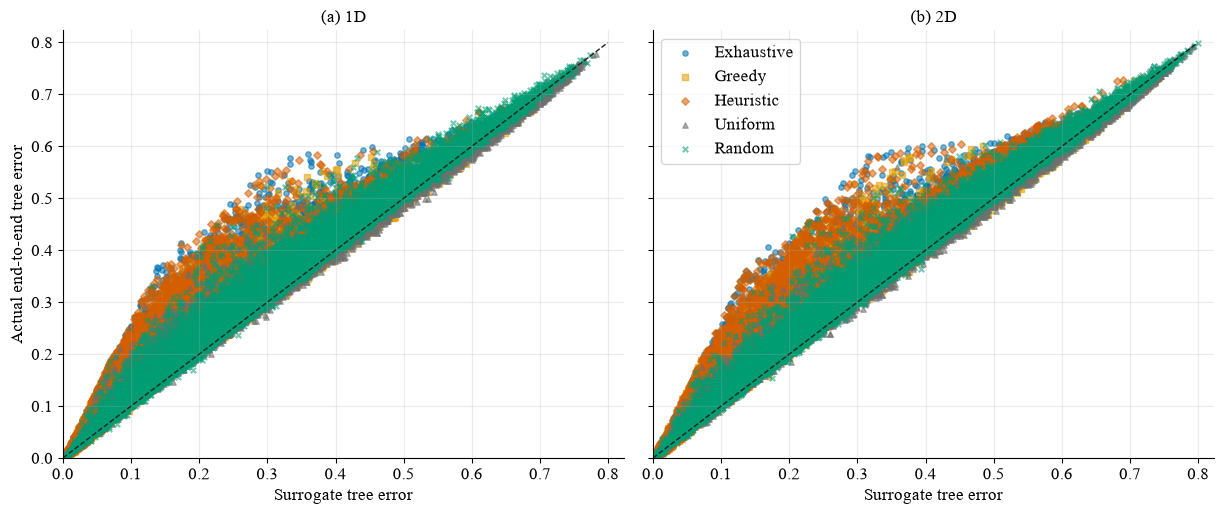

### Figure 2: Algorithm performance using actual error

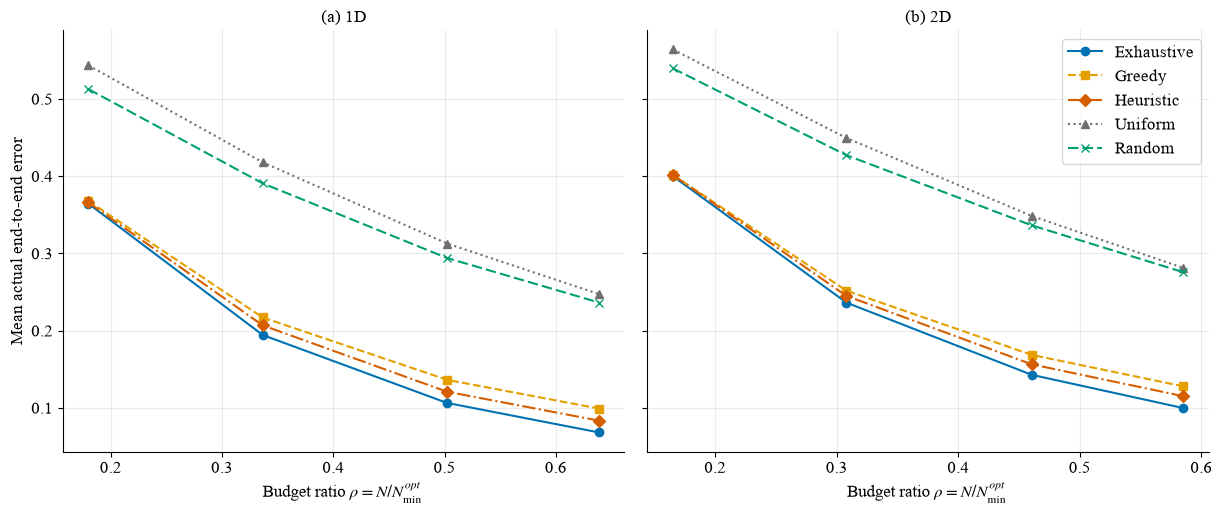

In [7]:
# Create, save, and display the two compact actual-error paper figures inline.
for title, figure in actual_error_analysis.make_combined_actual_error_plots(
    compact_records_by_dataset,
    ACTUAL_RESULTS_ROOT,
    run_scope=COMPACT_RUN_SCOPE,
):
    display(Markdown(f"### {title}"))
    display(figure)
    plt.close(figure)


## Patterns To Report

Use this final section as the paper-writing checklist. It identifies the only figures and numerical summaries intended for the paper and states the interpretation without overstating what the surrogate validation proves.


In [8]:
print("Paper figures to include")
print("1. Figure 1: surrogate final error vs actual final error, with 1D and 2D panels and y=x.")
print("2. Figure 2: mean actual end-to-end error vs budget ratio, with 1D and 2D panels.")

print("\nPaper-number checklist")
print("- Bias and MAE by dimension and method: calibration of the surrogate.")
print("- Pearson/Spearman by dimension and method, plus pooled all-method values: ranking proxy strength.")
print("- Within-budget Pearson/Spearman: checks whether pooled correlation is driven only by budget trend.")
print("- Method-ranking agreement: how often surrogate-best is also actual-best.")
print("- Mean actual errors and Tree-aware reduction vs Greedy: whether conclusions survive actual evaluation.")

print("\nInterpretation patterns")
print("- High correlation supports the surrogate as a ranking proxy, not as exact calibration.")
print("- Bias > 0 means the surrogate underestimates actual error on average; bias < 0 means it overestimates.")
print("- If within-budget correlations remain high, the relationship is not only due to the shared decrease with budget.")
print("- If Tree-aware actual error is below Greedy, the algorithmic ranking survives actual-error reevaluation.")
print("- The Exhaustive curve is surrogate-exhaustive reevaluated with actual error, not an actual-error optimum.")

Paper figures to include
1. Figure 1: surrogate final error vs actual final error, with 1D and 2D panels and y=x.
2. Figure 2: mean actual end-to-end error vs budget ratio, with 1D and 2D panels.

Paper-number checklist
- Bias and MAE by dimension and method: calibration of the surrogate.
- Pearson/Spearman by dimension and method, plus pooled all-method values: ranking proxy strength.
- Within-budget Pearson/Spearman: checks whether pooled correlation is driven only by budget trend.
- Method-ranking agreement: how often surrogate-best is also actual-best.
- Mean actual errors and Tree-aware reduction vs Greedy: whether conclusions survive actual evaluation.

Interpretation patterns
- High correlation supports the surrogate as a ranking proxy, not as exact calibration.
- Bias > 0 means the surrogate underestimates actual error on average; bias < 0 means it overestimates.
- If within-budget correlations remain high, the relationship is not only due to the shared decrease with budget.
- 